# DTU dataset, anechoic room: forward models

Converging evidence from an independent two-talker EEG dataset: Fuglsang, Dau & Hjortkjaer 2017, NeuroImage 156:435-444 (Zenodo 1199011; 18 subjects, 64-channel EEG, two talkers at +-60 degrees, attend one). That paper decoded attention; here the same data go through the forward models of this project, cell for cell as `diotic.ipynb`.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG: the raw recordings, preprocessed as this project's pipeline: bad channels by neighbour correlation, 0.5-20 Hz, mastoid reference, extended-infomax ICA with ICLabel (eye blinks, heart beats at >= 0.9), 64 Hz; trials cut at the trigger events as the authors' script does
- Trials: from the authors' trial table (stories, attended talker, single or two talkers, room)
- Predictors: 8-band gammatone envelope and onsets, made exactly as this project's; the mixture from the two stories summed (the rooms were simulated at presentation, so the exact mixture at the ears is not available)
- TRFs: the same boosting settings (-100 to 400 ms, 50 ms basis, l1, cross-validated)
- Tests: as this project's two-talker notebooks

**ROI:** this project's clean-speech ROI (`roi.txt`), found from the cocktail clean-speech whole-scalp tests (`clean.ipynb`). Every model test below runs within it (one-tailed TFCE in the ROI, and the ROI-averaged t-test), as in this project's two-talker notebooks, and every response function is averaged over it.

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [64]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

## DTU, anechoic room

In [65]:
# Reads this room's results from the cluster and sets the ROI: this project's clean-speech ROI (roi.txt),
# found from the cocktail clean-speech whole-scalp tests. Every test below runs within it.
ROI = dtu_setup('anechoic')

DTU anechoic: 18 subjects, 20 trials of 50 s each.
ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Every model test within the ROI above; ROI means and TRFs in the same ROI.


In [66]:
# All subjects' full-model TRFs, with the same columns as the cocktail notebooks' data_full
data_full = dtu_trfs('anechoic')

<small>

**Stream-level tests: each stream's envelope + onsets removed together**

- A stream = one talker's (or the mixture's) envelope + onsets
- Asks whether the brain tracks that stream at all, beyond the other two
- Can be significant when neither the envelope nor the onsets alone are

</small>

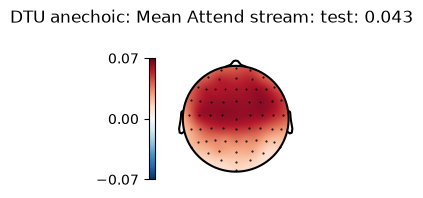

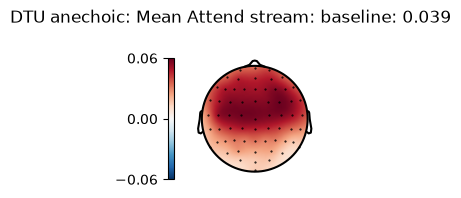

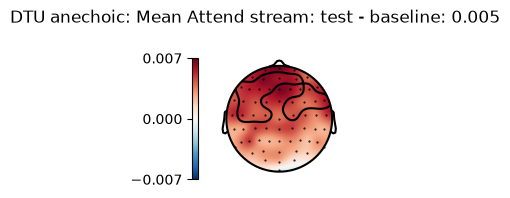

In [67]:
# Attend stream (envelope + onsets) unique contribution (DTU anechoic)
data, diff, result = dtu_model_test('Attend stream', 'anechoic')
show_topomap_trio(data, diff, result, 'Attend stream', 'DTU anechoic', None)

In [68]:
display(result)
print(f"Attend stream (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Attend stream (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Attend stream (DTU anechoic): TFCE t_max = 5.24, p < 0.001
Attend stream (DTU anechoic): ROI model comparison t(17) = 4.785, p = 0.0001


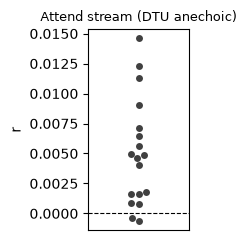

In [69]:
p = show_subject_swarm(diff, 'Attend stream', 'DTU anechoic')

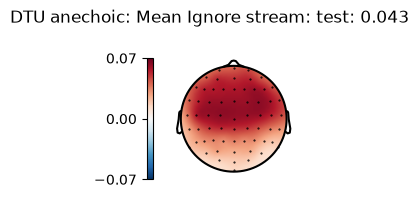

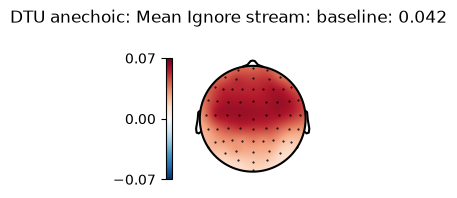

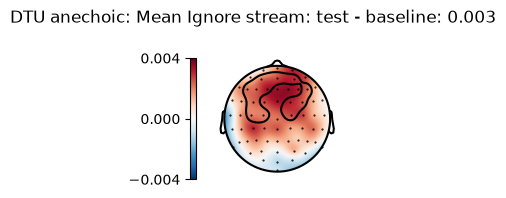

In [70]:
# Ignore stream (envelope + onsets) unique contribution (DTU anechoic)
data, diff, result = dtu_model_test('Ignore stream', 'anechoic')
show_topomap_trio(data, diff, result, 'Ignore stream', 'DTU anechoic', None)

In [71]:
display(result)
print(f"Ignore stream (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Ignore stream (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .012>

Ignore stream (DTU anechoic): TFCE t_max = 3.34, p = 0.012
Ignore stream (DTU anechoic): ROI model comparison t(17) = 2.592, p = 0.0095


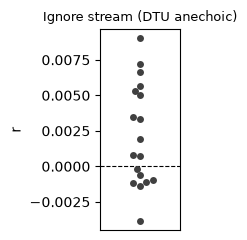

In [72]:
p = show_subject_swarm(diff, 'Ignore stream', 'DTU anechoic')

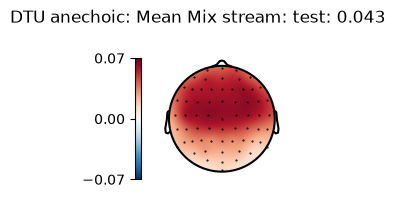

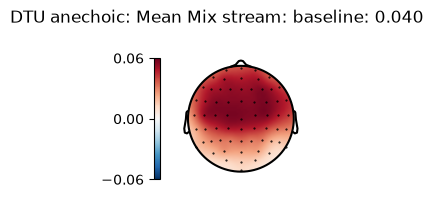

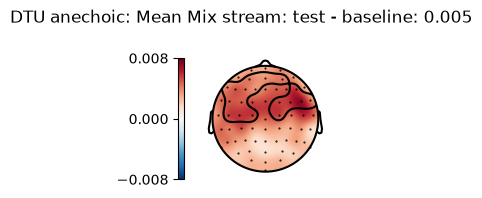

In [73]:
# Mix stream (envelope + onsets) unique contribution (DTU anechoic)
data, diff, result = dtu_model_test('Mix stream', 'anechoic')
show_topomap_trio(data, diff, result, 'Mix stream', 'DTU anechoic', None)

In [74]:
display(result)
print(f"Mix stream (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Mix stream (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Mix stream (DTU anechoic): TFCE t_max = 5.59, p < 0.001
Mix stream (DTU anechoic): ROI model comparison t(17) = 5.887, p = 0.0000


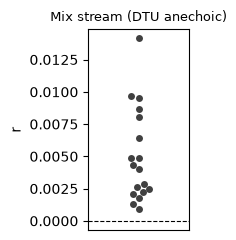

In [75]:
p = show_subject_swarm(diff, 'Mix stream', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, onset attend unique contribution**

- Attended onsets add predictive power: t_max = 6.32, p < 0.001
- All tests here are within the auditory cortex region
- Best overall model fit: r = 0.158

</small>

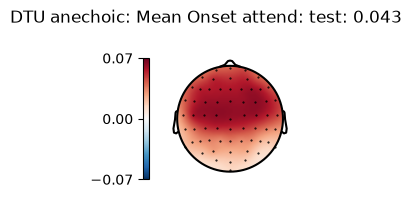

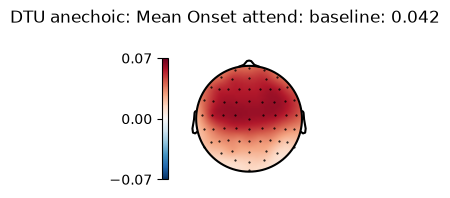

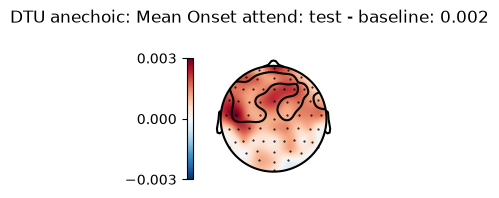

In [76]:
# Onset attend unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = dtu_model_test('Onset attend', 'anechoic')
show_topomap_trio(data, diff, result, 'Onset attend', 'DTU anechoic', None)

In [77]:
display(result)
print(f"Onset attend (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset attend (DTU anechoic): TFCE t_max = 4.97, p < 0.001
Onset attend (DTU anechoic): ROI model comparison t(17) = 3.279, p = 0.0022


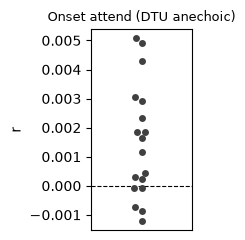

In [78]:
p = show_subject_swarm(diff, 'Onset attend', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, onset ignore unique contribution**

- Ignored onsets add predictive power: t_max = 6.70, p < 0.001
- Key finding: the ignored speaker is represented even after accounting for the mixture and the attended speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


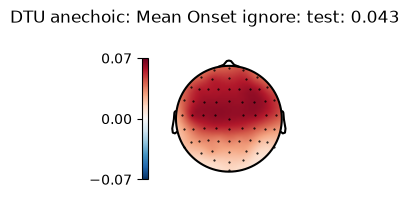

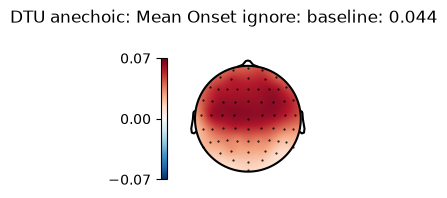

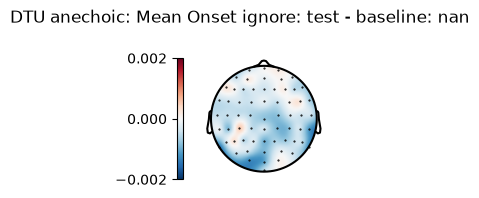

In [79]:
# Onset ignore unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = dtu_model_test('Onset ignore', 'anechoic')
show_topomap_trio(data, diff, result, 'Onset ignore', 'DTU anechoic', None)

In [80]:
display(result)
print(f"Onset ignore (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .860>

Onset ignore (DTU anechoic): TFCE t_max = 0.66, p = 0.860
Onset ignore (DTU anechoic): ROI model comparison t(17) = -1.041, p = 0.8437


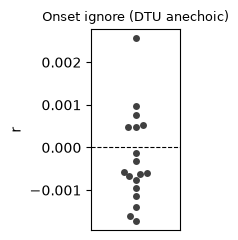

In [81]:
p = show_subject_swarm(diff, 'Onset ignore', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, onset mix unique contribution**

- Mixture onsets add predictive power: t_max = 8.61, p < 0.001

</small>

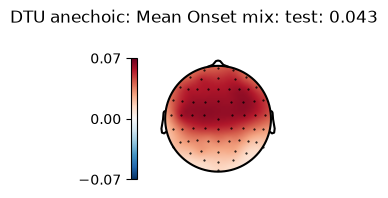

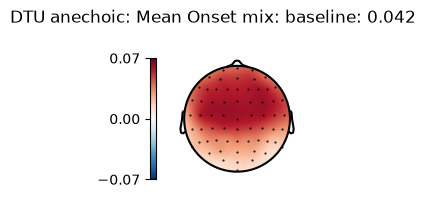

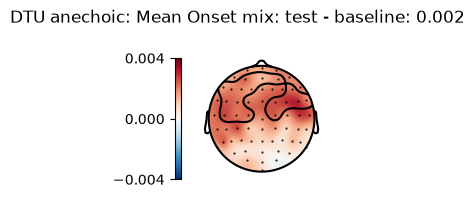

In [82]:
# Onset mix unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = dtu_model_test('Onset mix', 'anechoic')
show_topomap_trio(data, diff, result, 'Onset mix', 'DTU anechoic', None)

In [83]:
display(result)
print(f"Onset mix (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset mix (DTU anechoic): TFCE t_max = 6.52, p < 0.001
Onset mix (DTU anechoic): ROI model comparison t(17) = 7.017, p = 0.0000


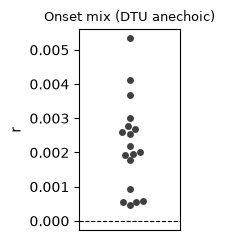

In [84]:
p = show_subject_swarm(diff, 'Onset mix', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope attend unique contribution**

- Attended envelope adds predictive power: t_max = 7.37, p < 0.001

</small>

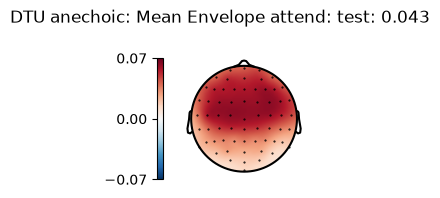

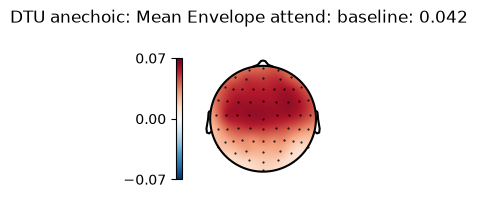

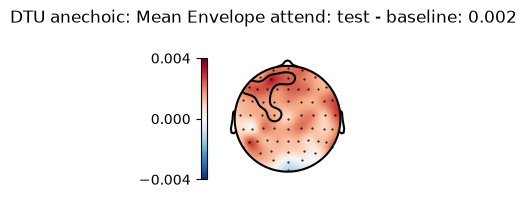

In [85]:
# Envelope attend unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = dtu_model_test('Envelope attend', 'anechoic')
show_topomap_trio(data, diff, result, 'Envelope attend', 'DTU anechoic', None)

In [86]:
display(result)
print(f"Envelope attend (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .013>

Envelope attend (DTU anechoic): TFCE t_max = 2.95, p = 0.013
Envelope attend (DTU anechoic): ROI model comparison t(17) = 2.592, p = 0.0095


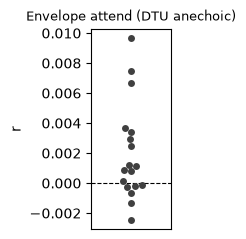

In [87]:
p = show_subject_swarm(diff, 'Envelope attend', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope ignore unique contribution**

- Ignored envelope adds predictive power: t_max = 6.28, p < 0.001

</small>

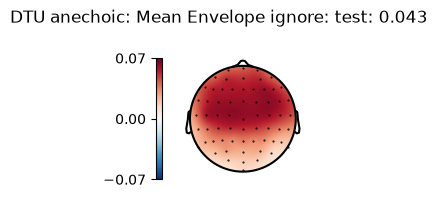

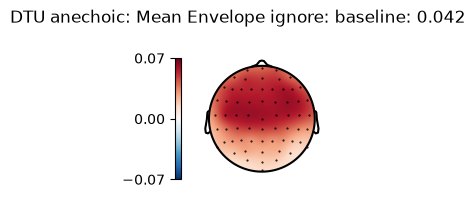

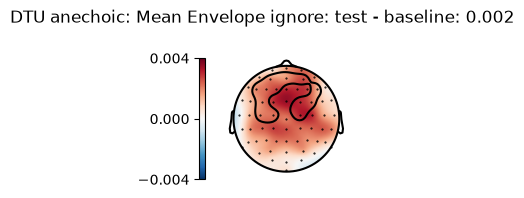

In [88]:
# Envelope ignore unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = dtu_model_test('Envelope ignore', 'anechoic')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'DTU anechoic', None)

In [89]:
display(result)
print(f"Envelope ignore (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .006>

Envelope ignore (DTU anechoic): TFCE t_max = 3.75, p = 0.006
Envelope ignore (DTU anechoic): ROI model comparison t(17) = 2.836, p = 0.0057


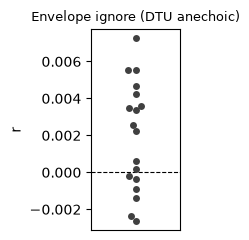

In [90]:
p = show_subject_swarm(diff, 'Envelope ignore', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope mix unique contribution**

- Mixture envelope adds predictive power: t_max = 5.70, p < 0.001

</small>

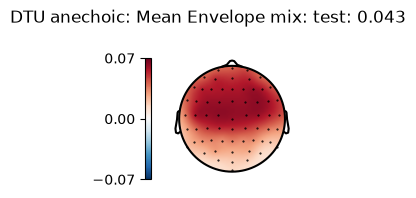

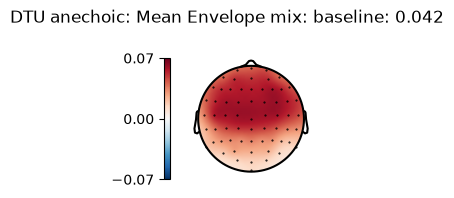

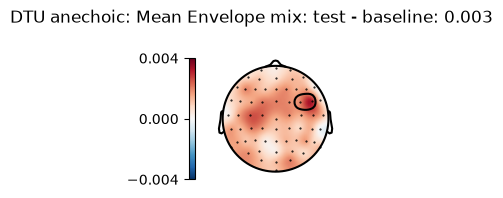

In [91]:
# Envelope mix unique contribution (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = dtu_model_test('Envelope mix', 'anechoic')
show_topomap_trio(data, diff, result, 'Envelope mix', 'DTU anechoic', None)

In [92]:
display(result)
print(f"Envelope mix (DTU anechoic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (DTU anechoic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .009>

Envelope mix (DTU anechoic): TFCE t_max = 3.56, p = 0.009
Envelope mix (DTU anechoic): ROI model comparison t(17) = 2.596, p = 0.0094


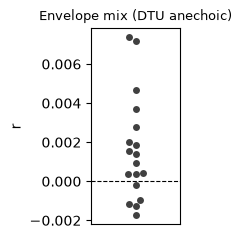

In [93]:
p = show_subject_swarm(diff, 'Envelope mix', 'DTU anechoic')

<small>

**Brodbeck et al. 2020: Two talkers, STRFs (mix, attend, ignore)**

- Onsets: same positive-then-negative shape as for clean speech
- Positive peak: earliest and biggest for the mixture
- Negative peak: only for the mixture and the attended speaker, none for the ignored speaker
- Envelope: lower amplitude, but a strong attention effect (attended > ignored)

</small>

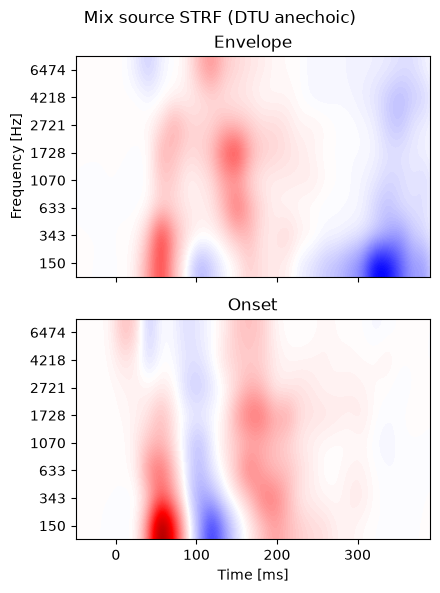

In [94]:
# Mix source STRF: envelope + onset (DTU anechoic)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (DTU anechoic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

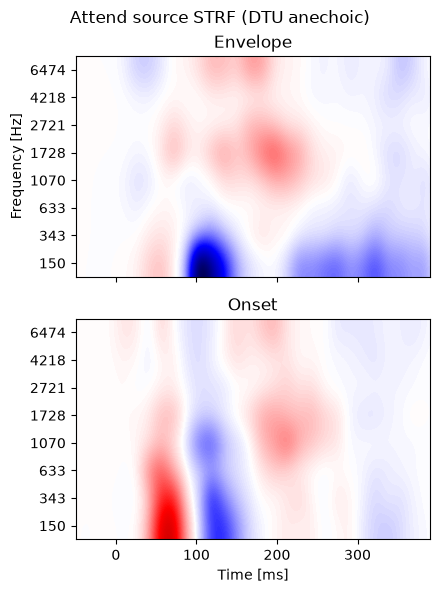

In [95]:
# Attend source STRF: envelope + onset (DTU anechoic)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (DTU anechoic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

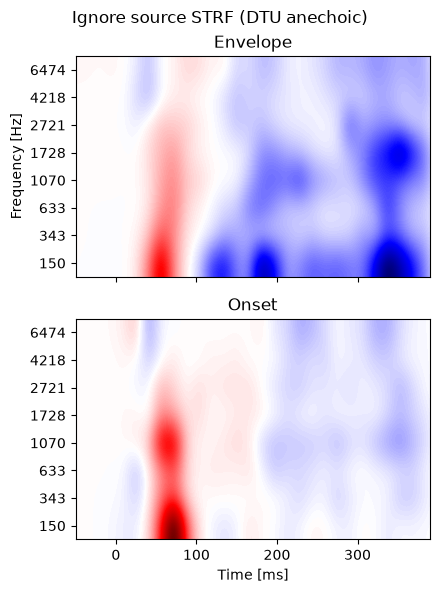

In [96]:
# Ignore source STRF: envelope + onset (DTU anechoic)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (DTU anechoic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, onset peak latencies**

- Positive peak: mixture 72 ms, attended 81 ms, ignored 89 ms
- Negative peak: mixture 136 ms, attended 150 ms, ignored none
- Peak search window: 20 to 200 ms (this notebook: the same)

</small>

In [97]:
# Onset attend peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (DTU anechoic) positive peak: 62 ms, amp 0.003898
Onset attend (DTU anechoic) negative peak: 123 ms, amp -0.003165


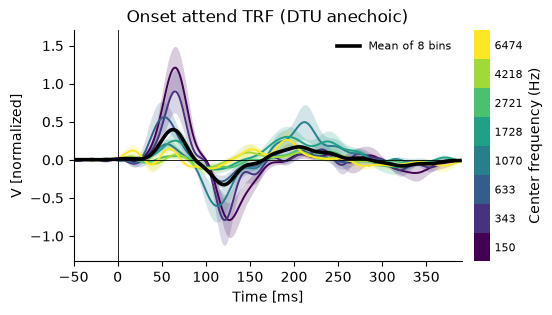

In [98]:
# Onset attend TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (DTU anechoic)')

In [99]:
# Onset ignore peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (DTU anechoic) positive peak: 67 ms, amp 0.002885
Onset ignore (DTU anechoic) negative peak: 192 ms, amp -0.0004085


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


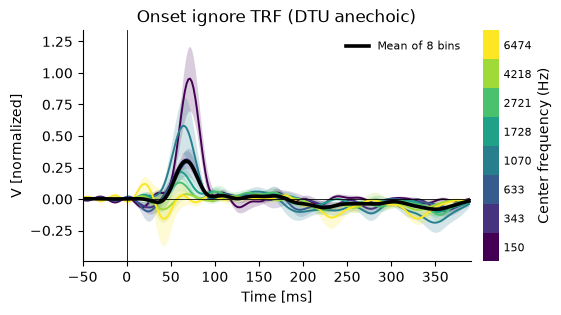

In [100]:
# Onset ignore TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (DTU anechoic)')

In [101]:
# Onset mix peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (DTU anechoic) positive peak: 59 ms, amp 0.00549
Onset mix (DTU anechoic) negative peak: 109 ms, amp -0.002595


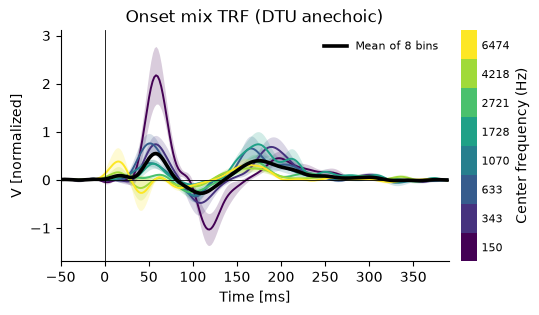

In [102]:
# Onset mix TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (DTU anechoic)')

<small>

**Brodbeck et al. 2020: Two talkers, envelope peaks**

- No envelope peak latencies reported; only the attention effect (see the attention-effect cell below)

</small>

In [103]:
# Envelope attend peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (DTU anechoic) positive peak: 184 ms, amp 0.001987
Envelope attend (DTU anechoic) negative peak: 108 ms, amp -0.00298


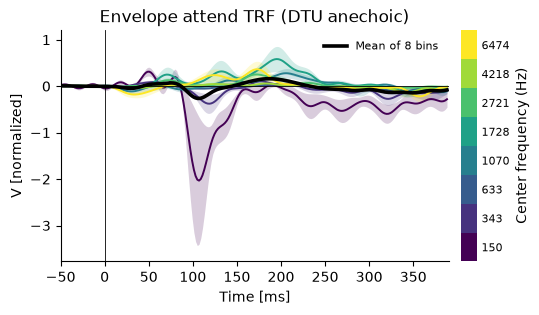

In [104]:
# Envelope attend TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (DTU anechoic)')

In [105]:
# Envelope ignore peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (DTU anechoic) positive peak: 67 ms, amp 0.001748
Envelope ignore (DTU anechoic) negative peak: 180 ms, amp -0.002052


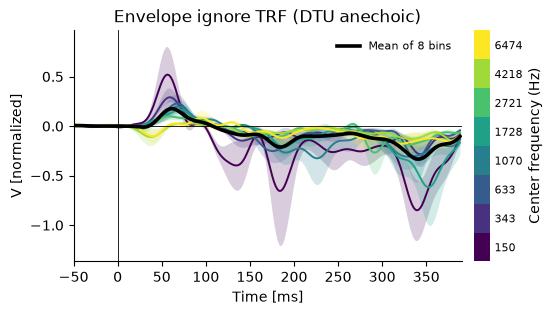

In [106]:
# Envelope ignore TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (DTU anechoic)')

In [107]:
# Envelope mix peak amplitude & timing (DTU anechoic)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (DTU anechoic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (DTU anechoic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (DTU anechoic) positive peak: 149 ms, amp 0.003724
Envelope mix (DTU anechoic) negative peak: 31 ms, amp -0.0004441


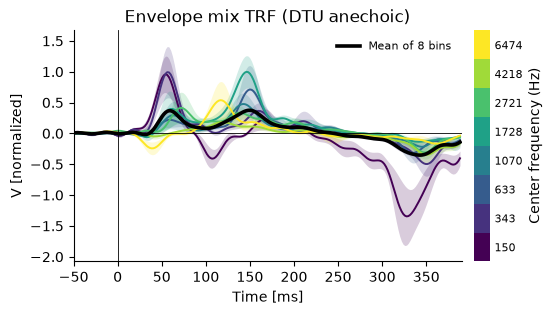

In [108]:
# Envelope mix TRF per frequency bin (DTU anechoic)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (DTU anechoic)')

<small>

**Brodbeck et al. 2020: Two talkers, onset peak comparison**

- Positive peak later for attended than mixture: 81 vs 72 ms, t(25) = 4.47, p < 0.001
- Positive peak later for ignored than mixture: 89 vs 72 ms, t(25) = 6.92, p < 0.001
- Positive peak bigger for mixture than attended: t(25) = 8.41, p < 0.001
- Positive peak bigger for mixture than ignored: t(25) = 7.66, p < 0.001
- Negative peak later for attended than mixture: 150 vs 136 ms, t(25) = 3.20, p = 0.004
- Negative peak amplitude: no difference (mixture vs attended), t(25) = 1.56, p = 0.132

</small>

In [109]:
# Onset peak comparison across mix, attend, and ignore (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


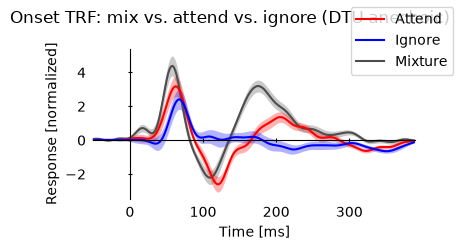

In [110]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (DTU anechoic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [111]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                 56       0.00695
S2        mix                 56       0.01314
S3        mix                 72      0.009166
S4        mix                 58      0.006984
S5        mix                 72      0.001653
S6        mix                 62      0.002671
S7        mix                 64      0.005002
S8        mix                 48      0.003089
S9        mix                 48      0.007819
S10       mix                 41      0.009952
S11       mix                 54      0.000415
S12       mix                 72     0.0009684
S13       mix                 52      0.001361
S14       mix                 68      0.005011
S15       mix                 54       0.01099
S16       mix                 56      0.008594
S17       mix                 70     0.0006566
S18       mix                 56      0.004402
S1        attend              62      0.001742
S2        attend              58      0.00809

In [112]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = -1.15 p = .267,t17 = -4.60*** p < .001
attend,,t17 = -2.01 p = .061


,attend,ignore
mix,t17 = -5.05*** p < .001,t17 = -26.08*** p < .001
attend,,t17 = -18.63*** p < .001


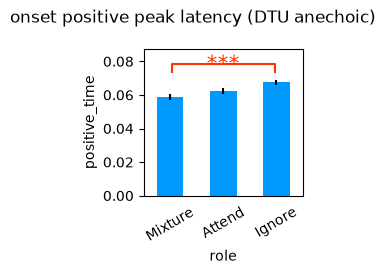

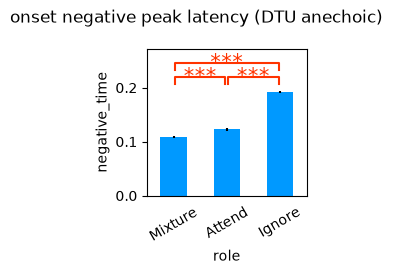

In [113]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (DTU anechoic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (DTU anechoic)')
p.set_xtick_rotation(30)

In [114]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 1.41 p = .176,t17 = 2.47* p = .024
attend,,t17 = 1.15 p = .265


,attend,ignore
mix,t17 = 0.74 p = .472,t17 = -3.10** p = .006
attend,,t17 = -4.01*** p < .001


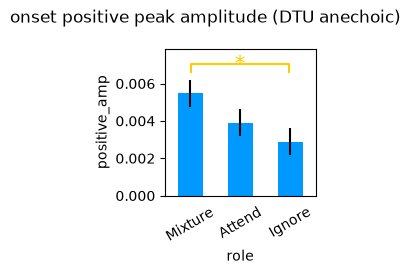

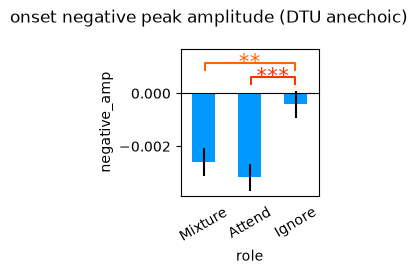

In [115]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (DTU anechoic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (DTU anechoic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope peak comparison**

- No envelope peak comparison reported

</small>

In [116]:
# Envelope peak comparison across mix, attend, and ignore (DTU anechoic)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

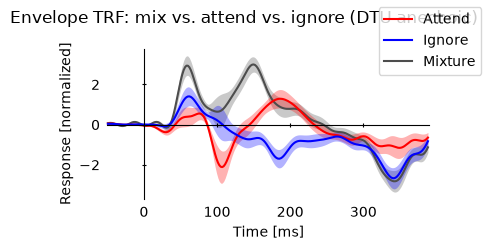

In [117]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (DTU anechoic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [118]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                152       0.01108
S2        mix                152      0.003446
S3        mix                170      0.002241
S4        mix                127       0.00627
S5        mix                166      0.002747
S6        mix                144      0.006558
S7        mix                144       0.00128
S8        mix                162      0.005674
S9        mix                136       0.00262
S10       mix                148      0.002028
S11       mix                156      0.004168
S12       mix                150     0.0006121
S13       mix                136      0.006252
S14       mix                158      0.001777
S15       mix                136      0.001002
S16       mix                144      0.001306
S17       mix                148      0.002755
S18       mix                152      0.005215
S1        attend             171       0.00518
S2        attend             189     0.000789

In [119]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = -9.49*** p < .001,t17 = 21.99*** p < .001
attend,,t17 = 38.57*** p < .001


,attend,ignore
mix,t17 = -19.28*** p < .001,t17 = -39.76*** p < .001
attend,,t17 = -16.47*** p < .001


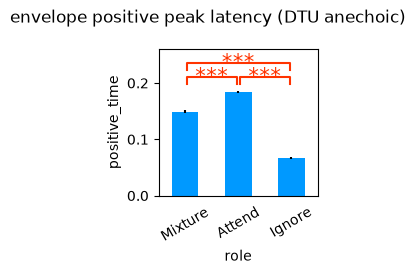

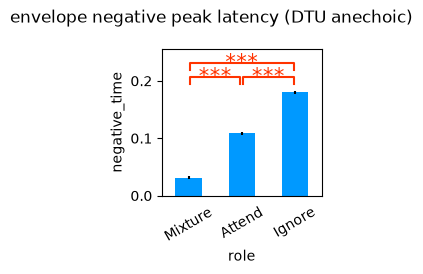

In [120]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (DTU anechoic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (DTU anechoic)')
p.set_xtick_rotation(30)

In [121]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 2.46* p = .025,t17 = 3.09** p = .007
attend,,t17 = 0.33 p = .749


,attend,ignore
mix,t17 = 1.74 p = .101,t17 = 2.12* p = .049
attend,,t17 = -0.56 p = .584


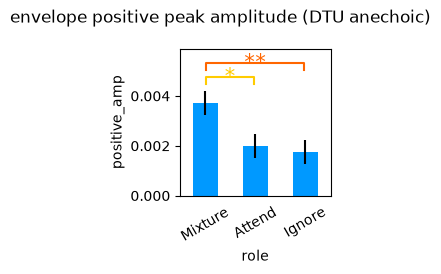

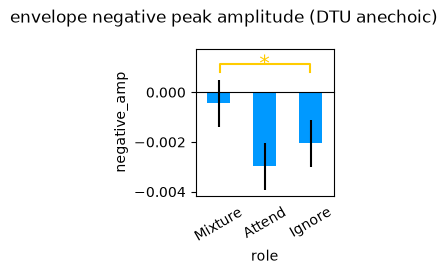

In [122]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (DTU anechoic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (DTU anechoic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope attention effect (attend - ignore)**

- Negative peak at about 100 ms
- Positive peak at about 200 ms
- The attention effect starts almost as early as the earliest response

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU anechoic): bins that differ from 0 somewhere: 1728 Hz, 2721 Hz, 4218 Hz


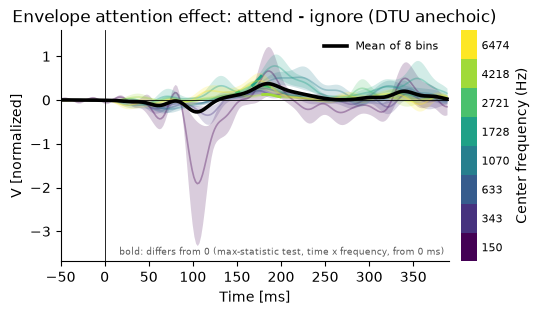

In [123]:
# Envelope attention effect: attend - ignore (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (DTU anechoic)', subtract='bg_gammatone_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU anechoic): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 164-211 ms (p = 0.009)


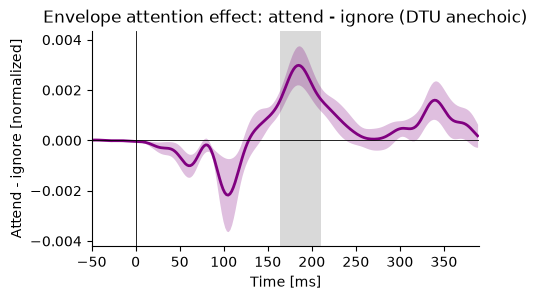

In [124]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_8', 'bg_gammatone_8', 'Envelope attention effect: attend - ignore (DTU anechoic)')

<small>

**Brodbeck et al. 2020: Two talkers, onset attention effect (attend - ignore)**

- Early positive peak: little or no attention effect
- Later negative peak (about 136 to 150 ms): attended only, so a clear attention effect there

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU anechoic): bins that differ from 0 somewhere: 150 Hz, 633 Hz, 1070 Hz, 1728 Hz


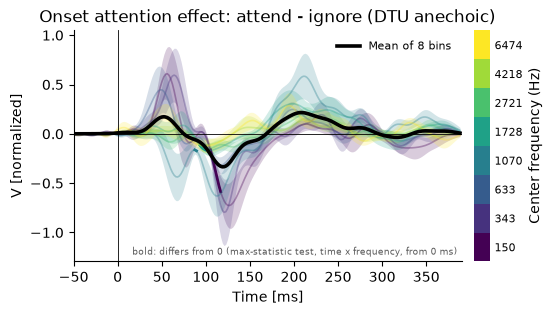

In [125]:
# Onset attention effect: attend - ignore (DTU anechoic)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (DTU anechoic)', subtract='bg_gammatone_on_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU anechoic): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 97-130 ms (p < 0.001); 207-212 ms (p = 0.040)


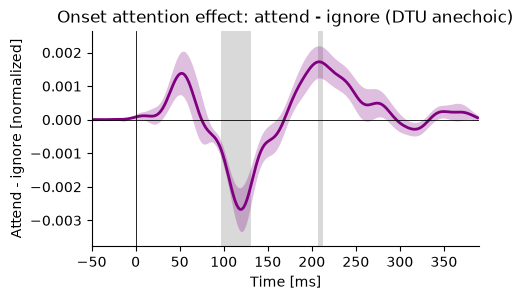

In [126]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_on_8', 'bg_gammatone_on_8', 'Onset attention effect: attend - ignore (DTU anechoic)')